# P1.04 — Renting or buying?

**Question:** RQ1.6 (how does the total cost of buying compare with renting: interest, down payment, taxes,
maintenance and other costs?). Related: RQ1.7 (mortgage rates), RQ4.2 (where).

The comparison is the user cost of housing. A year of owning costs, as a share of the price, the interest on the
loan, the return forgone on the deposit, property tax (IMI), upkeep, and the one-off costs of buying spread over the
years the home is held. A year of renting costs the **rent yield** (twelve rents over the price). The difference is
the **break-even appreciation**: the yearly price growth at which owning costs the same as renting. Below it, owning
is cheaper only if prices rise; above it, owning is cheaper even if they fall (negative values).

Every share and rate other than the mortgage rate and the IMI rate is an **assumption** (`config.py`,
`docs/methodology.md`), not an estimate; the sensitivity section shows how far each moves the answer.
Rents are of new leases and exist for 2020-2024 only (33 leases needed per municipality), so the municipal evidence
is five years, and the national history is built by anchoring the OECD price-to-rent index to them.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import descriptive as desc
from pthousing.config import EXPECTED_APPRECIATION_PCT
from pthousing.features import rent_vs_buy as rvb
from pthousing.viz import charts, dashboard, maps, style

style.apply_style()
panel = rvb.add_indicators(dashboard.load_panel())
long = dashboard.load_long_run().set_index("year")
y24 = panel[panel["year"] == 2024].set_index("muni_code")
geometry = maps.municipality_geometry()
n_rent = int(y24["rent_yield_pct"].notna().sum())
print(
    f"municipalities with a price and a rent in 2024: {n_rent} of {len(y24)}; "
    f"IMI rate filled with the year mean in {int(y24['imi_urban_pct'].isna().sum())}"
)

municipalities with a price and a rent in 2024: 212 of 308; IMI rate filled with the year mean in 8


## Step 1 — The municipal picture, 2020-2024
Median over the municipalities with a rent in all five years (the same places every year), so a changing sample is
not read as a trend. The cost of owning hardly differs between municipalities (one national mortgage rate, similar IMI
rates); what differs is the rent yield. Cash cost over rent is the yearly bill of an owner (loan payments **including
principal**, IMI, upkeep) divided by the rent: above 1, the monthly bill of buying is higher than renting.

In [2]:
w = panel[panel["year"].between(2020, 2024)]
columns = {
    "rent_yield_pct": "Rent yield (% of price)",
    "owner_cost_pct": "Yearly cost of owning (% of price)",
    "breakeven_pct": "Break-even price growth (% a year)",
    "cash_cost_vs_rent": "Owner's cash bill / rent",
}
balanced = desc.balanced_sample(w, list(columns), list(range(2020, 2025)))
trend = balanced.groupby("year")[list(columns)].median().rename(columns=columns).round(2)
print(f"{balanced['muni_code'].nunique()} municipalities with every value in all five years")
style.save_table(trend.reset_index(), "p1", "rent_vs_buy_trend_2020_2024")
trend

187 municipalities with every value in all five years


,Rent yield (% of price),Yearly cost of owning (% of price),Break-even price growth (% a year),Owner's cash bill / rent
year,,,,
2020,5.50,3.13,-2.36,0.77
2021,5.46,2.92,-2.54,0.76
2022,5.15,3.66,-1.49,0.88
2023,5.40,5.76,0.36,1.09
2024,5.52,5.87,0.37,1.09


## Step 2 — Thirty years, nationally
The OECD price-to-rent index covers 1988-2025, but an index is not a yield. Its level is set so that the implied yield
matches the municipal one on average over 2020-2024 (yield = scale / price-to-rent, new leases weighted); the shape
then comes from the OECD, whose rents cover **all** leases, not only new ones. The two differ: existing leases follow
inflation, new leases follow the market. The check below shows how far the anchored series is from the measured one.
IMI is the mean municipal rate (2012 on; the 2012 rate before). Mortgage rate: agreed rate on new loans (Banco de
Portugal, from 2003). Forward growth is the nominal OECD price index over the next five years.

In [3]:
measured = (
    w.dropna(subset=["rent_yield_pct", "new_leases_n"])
    .groupby("year")
    .apply(
        lambda g: np.average(g["rent_yield_pct"], weights=g["new_leases_n"]), include_groups=False
    )
)
p2r = long["price_to_rent_b2015"]
scale = rvb.calibrate_yield_scale(measured, p2r)
rate = panel.drop_duplicates("year").set_index("year")["mortgage_rate_new_lt1y_pct"]
imi = panel.groupby("year")["imi_urban_pct"].mean().reindex(range(2003, 2026)).bfill()
nat = rvb.national_breakeven(p2r, rate, imi, scale)
nominal = long["hpi_nominal_b2015"]
forward = 100 * ((nominal.shift(-5) / nominal) ** (1 / 5) - 1)
check = pd.DataFrame(
    {"measured_yield_pct": measured, "anchored_yield_pct": nat["rent_yield_pct"]}
).dropna()
check["gap_pp"] = check["anchored_yield_pct"] - check["measured_yield_pct"]
style.save_table(check.round(2).reset_index(), "p1", "rent_vs_buy_anchor_check")
print(f"scale {scale:.0f}; yield = scale / price-to-rent")
check.round(2)

scale 818; yield = scale / price-to-rent


,measured_yield_pct,anchored_yield_pct,gap_pp
year,,,
2020,5.29,5.87,0.58
2021,5.09,5.47,0.38
2022,4.96,4.98,0.02
2023,5.18,4.82,-0.37
2024,5.26,4.72,-0.53


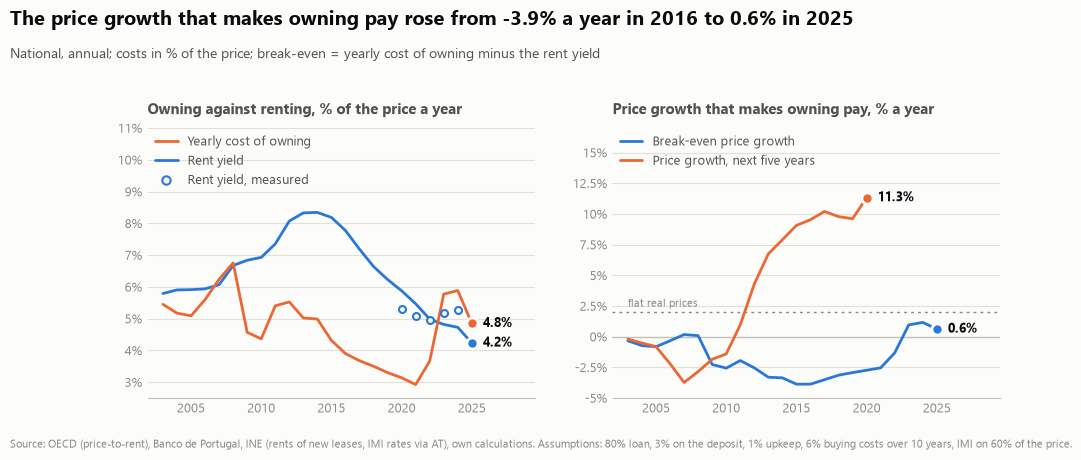

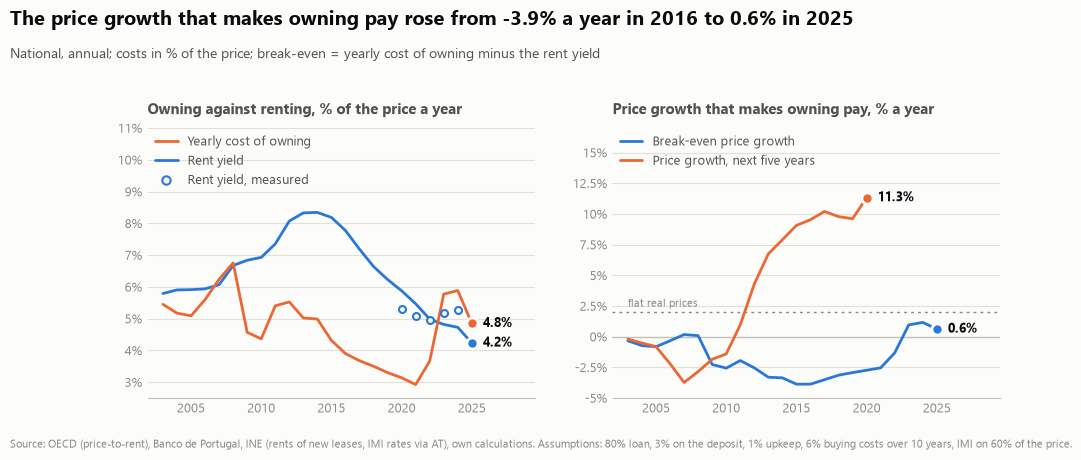

In [4]:
fig = charts.rent_vs_buy_long_run(
    nat, measured, forward.reindex(nat.index), EXPECTED_APPRECIATION_PCT
)
style.save_fig(fig, "p1", "rent_vs_buy_long_run")
fig

## Step 3 — Why the balance moved
The components of the cost of owning in three years of very different rates, against the rent yield. Prices barely
enter the cost: the price is the base, and the rate on it moved from 3.9% (2012) to 0.7% (2021) to 4.4% (2024).

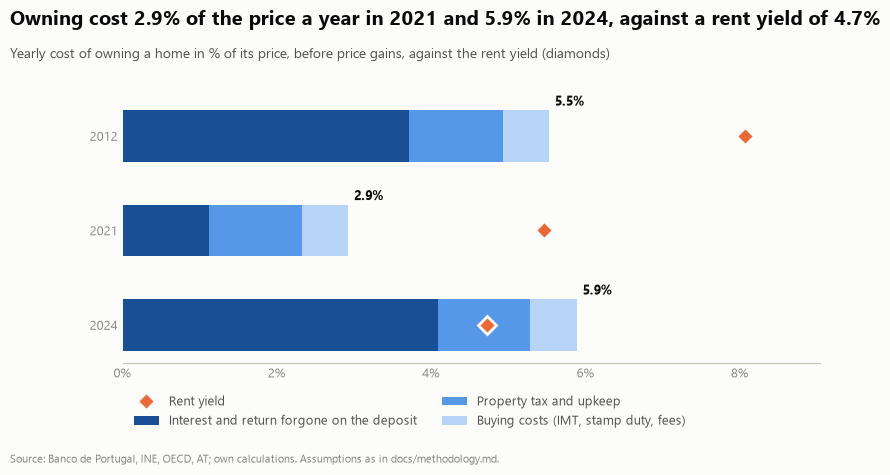

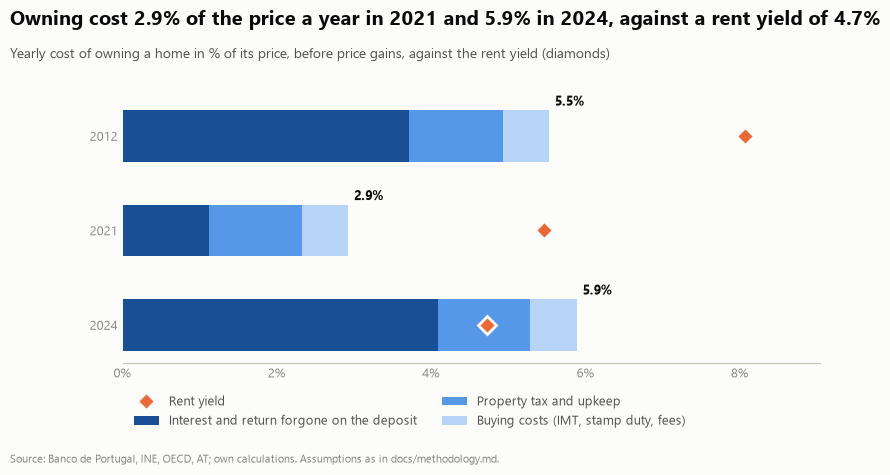

In [5]:
years = [2012, 2021, 2024]
stack = nat.loc[years, rvb.COMPONENTS]
fig = charts.owner_cost_stack(stack, nat.loc[years, "rent_yield_pct"])
style.save_fig(fig, "p1", "rent_vs_buy_cost_stack")
fig

## Step 4 — Where, 2024
Break-even price growth by municipality. Dark: even with prices rising faster than flat real prices (2% a year),
owning costs more than renting.

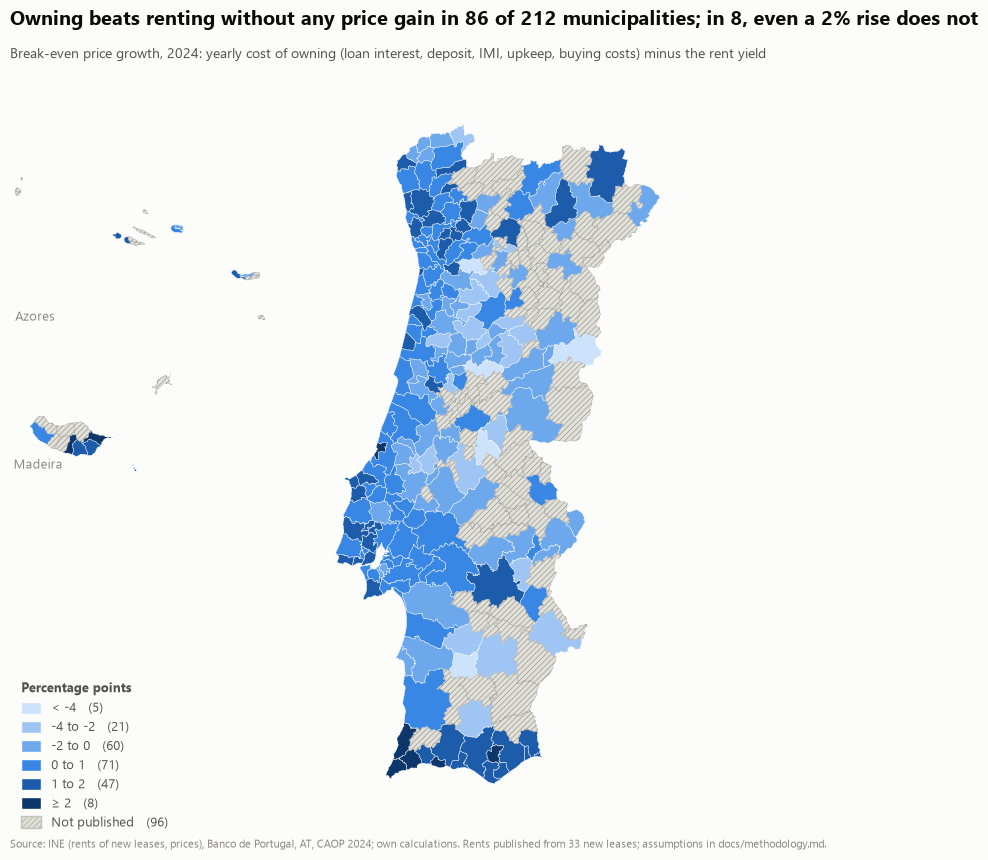

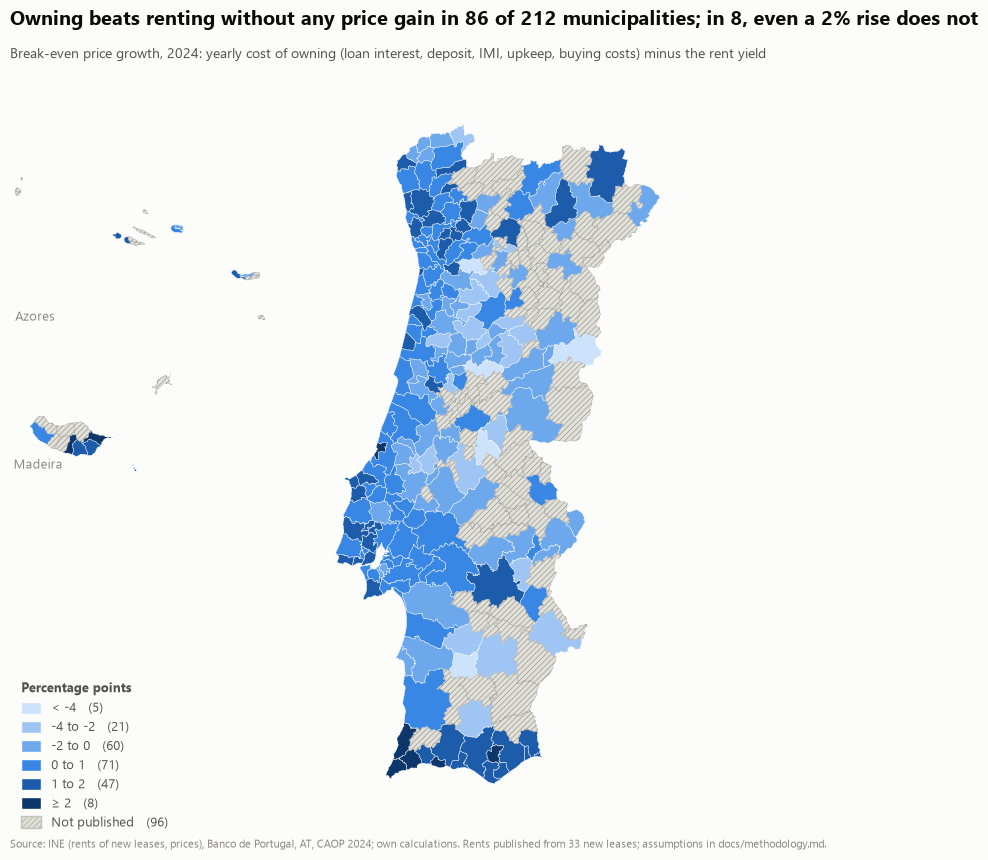

In [6]:
n_flat = int((y24["breakeven_pct"] > EXPECTED_APPRECIATION_PCT).sum())
n_neg = int((y24["breakeven_pct"] < 0).sum())
fig = maps.choropleth(
    y24["breakeven_pct"], geometry, [-4, -2, 0, 1, 2], style.SEQUENTIAL_6,
    f"Owning beats renting without any price gain in {n_neg} of {n_rent} municipalities; in {n_flat}, even a 2% rise does not",
    "Break-even price growth, 2024: yearly cost of owning (loan interest, deposit, IMI, upkeep, buying costs) minus the rent yield",
    "Source: INE (rents of new leases, prices), Banco de Portugal, AT, CAOP 2024; own calculations. Rents published from 33 new leases; assumptions in docs/methodology.md.",
    "Percentage points", fmt="{:g}", suffix="",
)  # fmt: skip
style.save_fig(fig, "p1", "rent_vs_buy_breakeven_map_2024")
fig

### The barrier is cash, not the monthly bill
Owning can cost less per year and still be out of reach: the day of purchase needs the deposit (20% of the price) and the
buying costs (6%), in years of income. Map of that sum in 2024, all municipalities with a price and an income.

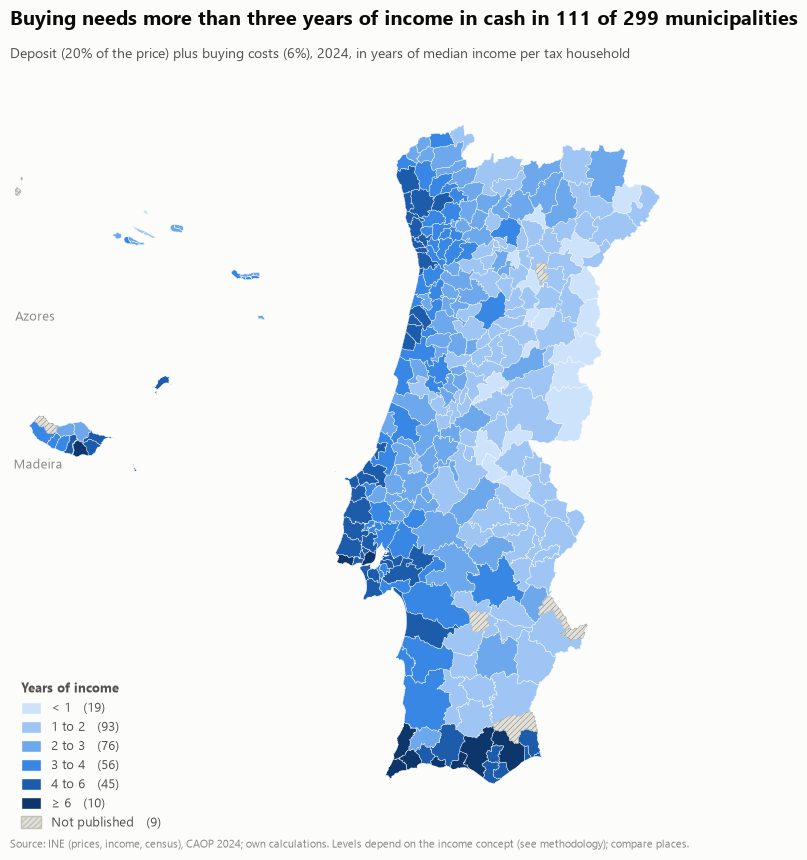

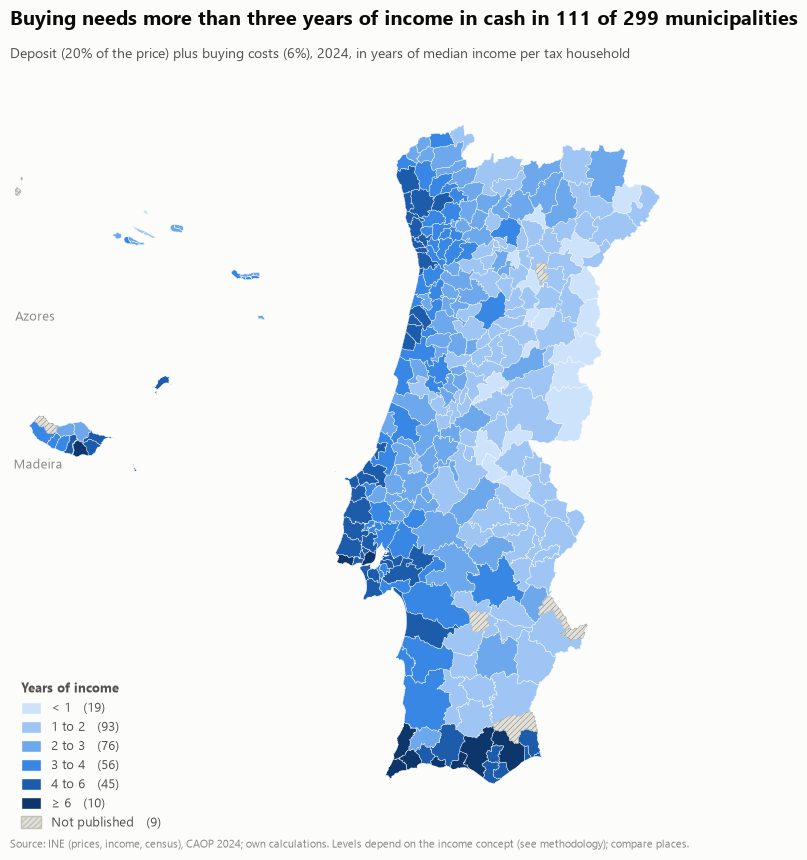

In [7]:
n_up = int(y24["upfront_cash_years"].notna().sum())
n3 = int((y24["upfront_cash_years"] > 3).sum())
fig = maps.choropleth(
    y24["upfront_cash_years"], geometry, [1, 2, 3, 4, 6], style.SEQUENTIAL_6,
    f"Buying needs more than three years of income in cash in {n3} of {n_up} municipalities",
    "Deposit (20% of the price) plus buying costs (6%), 2024, in years of median income per tax household",
    "Source: INE (prices, income, census), CAOP 2024; own calculations. Levels depend on the income concept (see methodology); compare places.",
    "Years of income", fmt="{:g}", suffix="",
)  # fmt: skip
style.save_fig(fig, "p1", "rent_vs_buy_upfront_cash_map_2024")
fig

## Step 5 — By type of place, 2024

In [8]:
groups = []
for column, label in (("density_class", "density"), ("coast_class", "coast")):
    g = (
        y24.groupby(column)
        .agg(
            municipalities_n=("breakeven_pct", "size"),
            with_rent_n=("rent_yield_pct", "count"),
            rent_yield_pct=("rent_yield_pct", "median"),
            breakeven_pct=("breakeven_pct", "median"),
            cash_cost_vs_rent=("cash_cost_vs_rent", "median"),
            pti_years=("pti_years", "median"),
            upfront_cash_years=("upfront_cash_years", "median"),
        )
        .reset_index()
        .rename(columns={column: "group"})
    )
    groups.append(g.assign(dimension=label))
by_type = pd.concat(groups)[
    ["dimension", "group", "municipalities_n", "with_rent_n", "rent_yield_pct", "breakeven_pct",
     "cash_cost_vs_rent", "pti_years", "upfront_cash_years"]
].round(2)  # fmt: skip
style.save_table(by_type, "p1", "rent_vs_buy_by_type_2024")
by_type

,dimension,group,municipalities_n,with_rent_n,rent_yield_pct,breakeven_pct,cash_cost_vs_rent,pti_years,upfront_cash_years
0,density,intermediate,84,78,5.18,0.69,1.15,13.22,3.44
1,density,rural,189,99,6.34,-0.44,0.95,6.81,1.77
2,density,urban,35,35,5.09,0.78,1.17,16.14,4.20
0,coast,coast,87,69,4.90,1.02,1.23,15.73,4.09
1,coast,estuary,9,9,5.28,0.68,1.15,13.22,3.44
2,coast,inland,212,134,6.21,-0.32,0.96,7.33,1.90


In [9]:
names = panel.drop_duplicates("muni_code").set_index("muni_code")[["muni_name", "district"]]
ranking = (
    names.join(
        y24[["rent_yield_pct", "owner_cost_pct", "breakeven_pct", "cash_cost_vs_rent", "upfront_cash_years", "new_leases_n"]]
    )
    .dropna(subset=["breakeven_pct"])
    .round(2)
    .sort_values("breakeven_pct", ascending=False)
    .reset_index()
)  # fmt: skip
style.save_table(ranking, "p1", "rent_vs_buy_by_municipality_2024")
ranking.head(8)

,muni_code,muni_name,district,rent_yield_pct,owner_cost_pct,breakeven_pct,cash_cost_vs_rent,upfront_cash_years,new_leases_n
0,0803,Aljezur,Faro,2.97,5.87,2.91,2.01,8.02,45.0
1,0815,Vila do Bispo,Faro,3.18,5.87,2.70,1.88,6.93,48.0
2,0807,Lagos,Faro,3.51,5.88,2.37,1.70,8.23,358.0
3,0812,São Brás de Alportel,Faro,3.62,5.94,2.31,1.66,5.11,109.0
4,1011,Nazaré,Leiria,3.69,5.96,2.28,1.64,5.89,199.0
5,3102,Câmara de Lobos,Ilha da Madeira,3.64,5.87,2.23,1.64,5.14,69.0
6,0806,Lagoa,Faro,3.80,5.91,2.11,1.58,6.76,236.0
7,3104,Machico,Ilha da Madeira,3.76,5.87,2.11,1.59,4.79,48.0


## Step 6 — How much the assumptions matter (2024, median municipality)
One assumption at a time, the others at their base value. The rate and the rent yield are observed; the rest are not.

In [10]:
grid = {
    "opportunity_rate_pct": [0.0, 5.0],
    "maintenance_pct": [0.5, 2.0],
    "buying_costs_pct": [3.0, 9.0],
    "holding_years": [5, 20],
    "imi_taxable_share": [0.3, 1.0],
    "ltv": [0.6, 0.9],
}
sens = rvb.breakeven_sensitivity(panel, 2024, grid).round(2)
style.save_table(sens, "p1", "rent_vs_buy_sensitivity_2024")
sens

,assumption,value,median_owner_cost_pct,median_breakeven_pct,share_owning_cheaper_pct
0,base,NaN,5.87,0.31,96.23
1,opportunity_rate_pct,0.0,5.27,-0.29,99.06
2,opportunity_rate_pct,5.0,6.27,0.71,89.62
3,maintenance_pct,0.5,5.37,-0.19,99.06
4,maintenance_pct,2.0,6.87,1.31,74.06
5,buying_costs_pct,3.0,5.57,0.01,98.11
6,buying_costs_pct,9.0,6.17,0.61,91.51
7,holding_years,5.0,6.47,0.91,86.32
8,holding_years,20.0,5.57,0.01,98.11
9,imi_taxable_share,0.3,5.78,0.22,96.70


## Key numbers

In [11]:
b = nat["breakeven_pct"]
flat = EXPECTED_APPRECIATION_PCT
print(
    f"Median municipality 2020 -> 2024: owner cash bill / rent {trend.iloc[0, 3]:.2f} -> {trend.iloc[-1, 3]:.2f}; "
    f"break-even {trend.iloc[0, 2]:.1f} -> {trend.iloc[-1, 2]:.1f} pp; rent yield {trend.iloc[0, 0]:.1f}% -> {trend.iloc[-1, 0]:.1f}%"
)
print(
    f"National break-even: {b.loc[2003]:.1f} (2003), min {b.min():.1f} ({b.idxmin()}), 2021 {b.loc[2021]:.1f}, 2024 {b.loc[2024]:.1f}, 2025 {b.loc[2025]:.1f}; "
    f"years below {flat}%: {int((b < flat).sum())} of {len(b)}"
)
hind = pd.concat([b, forward.reindex(b.index)], axis=1, keys=["be", "fwd"]).dropna()
print(
    f"Hindsight: owning paid (next-5-year growth > break-even) in {int((hind['fwd'] > hind['be']).sum())} of {len(hind)} years "
    f"({hind.index.min()}-{hind.index.max()}); worst shortfall {int((hind['fwd'] - hind['be']).idxmin())} ({(hind['fwd'] - hind['be']).min():.1f} pp)"
)
d24 = y24.dropna(subset=["breakeven_pct"])
print(
    f"2024: median break-even {d24['breakeven_pct'].median():.2f}; owning cheaper at flat real prices in {100 * (d24['breakeven_pct'] < flat).mean():.0f}%; "
    f"cheaper with no gain in {100 * (d24['breakeven_pct'] < 0).mean():.0f}%; bill above rent in {100 * (d24['cash_cost_vs_rent'] > 1).mean():.0f}%"
)
print(
    f"Cash on the day: median {y24['upfront_cash_years'].median():.1f} years of income (p10 {y24['upfront_cash_years'].quantile(0.1):.1f}, p90 {y24['upfront_cash_years'].quantile(0.9):.1f})"
)

Median municipality 2020 -> 2024: owner cash bill / rent 0.77 -> 1.09; break-even -2.4 -> 0.4 pp; rent yield 5.5% -> 5.5%
National break-even: -0.3 (2003), min -3.9 (2016), 2021 -2.5, 2024 1.2, 2025 0.6; years below 2.0%: 23 of 23
Hindsight: owning paid (next-5-year growth > break-even) in 15 of 18 years (2003-2020); worst shortfall 2007 (-3.9 pp)
2024: median break-even 0.31; owning cheaper at flat real prices in 96%; cheaper with no gain in 41%; bill above rent in 63%
Cash on the day: median 2.5 years of income (p10 1.2, p90 4.8)
